In [1]:
# mamba activate spatiocore_spatial_env
import tifffile
import os
from spatialdata.models import Image2DModel
import spatialdata_io
import pandas as pd
import geopandas as gpd
from shapely.geometry import Point
import numpy as np
from spatialdata.models import ShapesModel
import anndata
import scanpy as sc
from spatialdata import SpatialData
from spatialdata import polygon_query
from spatialdata import bounding_box_query
# from napari_spatialdata import Interactive
from spatialdata.models import TableModel
from spatialdata_plot.pl.utils import set_zero_in_cmap_to_transparent
from spatialdata import SpatialData
from napari.utils.colormaps import Colormap
from napari_spatialdata import Interactive
import spatialdata as sd
from scipy import ndimage as ndi
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib as mpl
import pickle
import squidpy as sq    

from spatialdata.transformations import (
    BaseTransformation,
    Identity,
    Sequence,
    align_elements_using_landmarks,
    get_transformation,
    set_transformation,
    Affine
)

In [2]:
import pickle
import sys


sys.path.insert(
    0,
    "/data/kanferg/Sptial_Omics/projects/NguyenLab/neuroblastoma"
)

from helper.utils import add_cluster_from_pickle
from helper.high_res_plot import PunchPlotter

In [3]:
import sys
sys.path.insert(
    0,
    "/data/kanferg/Sptial_Omics/projects/NatalieLab/liver_cancer/spatialomicstoolkit"
)
from spat_functions.triangle_heatmap import InteractionMatrixHeatmap

In [4]:
pathad = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
adata = sc.read_h5ad(os.path.join(pathad, "adata_nb_processed_v1.h5ad"))

In [5]:
pkl_dir = '/data/HiTIF/data/spatialomics/neuroblastoma/data/misc/subclusters_res_0p5'
adata = add_cluster_from_pickle(
    adata,
    os.path.join(pkl_dir, "0_subclusters_res_0p5.pkl"),
    "0_subclusters_res_0p5",match_col='cell_id'
)

0_subclusters_res_0p5
  total cells:   571009
  matched cells: 82571
  missing cells: 488438


In [6]:
with open(os.path.join(pkl_dir, "0_subclusters_res_0p5.pkl"), 'rb') as f:
    subclusters_res_0p5 = pickle.load(f)

In [7]:
subcluster0_to_annotation_v1 = {
    '1': "Adrenergic_Proliferating_NB",
    '2': "Schwann_CAF",
    '3': "Transitional_NB",
    '4': "Adrenergic_StemLike_NB",
    '5': "M2_TAM",
    '6': "CD8_Cytotoxic_TCell_PartiallyExhausted",
    '7': "Adrenergic_Cycling_NB",
    '8': "MonocyteDerived_TissueResident_Macrophage",
    '9': "Adrenergic_MYCNHigh_Metabolic_NB",
    '10': "Endothelial",
    '11': "Mesenchymal_NB",
    '12': "Adrenocortical_Steroidogenic",

    '0_0': "Transitional_NB",
    '0_1': "Metabolic_NB",
    '0_2': "Transitional_NB",
    '0_3': "MonocyteDerived_TissueResident_Macrophage",
}

adata.obs["annotation_v1"] = adata.obs["stlieden_ratio1p5_r13"].astype(str)

m = adata.obs["annotation_v1"].eq("0")
adata.obs.loc[m, "annotation_v1"] = ("0_" + adata.obs.loc[m, "0_subclusters_res_0p5"].astype(str))

adata.obs["annotation_v1"] = (adata.obs["annotation_v1"].map(subcluster0_to_annotation_v1).fillna("remove"))

adata_clean = adata[adata.obs["annotation_v1"] != "remove"].copy()

adata_clean.obs["annotation_v1"].value_counts()

annotation_v1
Transitional_NB                              122178
Schwann_CAF                                   75029
Adrenergic_StemLike_NB                        74982
Adrenergic_Proliferating_NB                   62085
M2_TAM                                        57523
CD8_Cytotoxic_TCell_PartiallyExhausted        56964
MonocyteDerived_TissueResident_Macrophage     47465
Adrenergic_MYCNHigh_Metabolic_NB              37216
Metabolic_NB                                  24861
Mesenchymal_NB                                 7724
Adrenergic_Cycling_NB                          1663
Endothelial                                     185
Adrenocortical_Steroidogenic                     82
Name: count, dtype: int64

In [8]:

adata_clean.obs["annotation_v1"].value_counts()

annotation_v1
Transitional_NB                              122178
Schwann_CAF                                   75029
Adrenergic_StemLike_NB                        74982
Adrenergic_Proliferating_NB                   62085
M2_TAM                                        57523
CD8_Cytotoxic_TCell_PartiallyExhausted        56964
MonocyteDerived_TissueResident_Macrophage     47465
Adrenergic_MYCNHigh_Metabolic_NB              37216
Metabolic_NB                                  24861
Mesenchymal_NB                                 7724
Adrenergic_Cycling_NB                          1663
Endothelial                                     185
Adrenocortical_Steroidogenic                     82
Name: count, dtype: int64

In [9]:
# Adding cluster metadata
annotation_key = 'annotation_v1'
cluster_col = 'stlieden_ratio1p5_r13' + "+ 0_subclusters_res_0p5"
adata_clean.uns[annotation_key] = {
    "description": "Manual annotation v1 for NB dataset.",
    "annotation_column": annotation_key,
    "source_cluster_column": cluster_col,
    "method": "SpatialLeiden, leiden subcluster (0)",
    "parameters": {
        "knn": 30,
        "leiden_resolution": 0.7,
        "spatialleiden_ratio": 1.5,
        "spatial_radius_um": 13,
    }}

annotation_colors = {
    # Neuroblastoma — adrenergic states: blues
    "Adrenergic_Proliferating_NB": "#084594",
    "Adrenergic_Cycling_NB": "#2171B5",
    "Adrenergic_StemLike_NB": "#4292C6",
    "Adrenergic_MYCNHigh_Metabolic_NB": "#6BAED6",

    # Neuroblastoma — transitional / mesenchymal states: greens
    "Transitional_NB": "#238B45",
    "Metabolic_NB": "#41AE76",
    "Mesenchymal_NB": "#74C476",

    # Myeloid — reds
    "M2_TAM": "#B2182B",
    "MonocyteDerived_TissueResident_Macrophage": "#FF5F59",

    # Lymphoid — orange
    "CD8_Cytotoxic_TCell_PartiallyExhausted": "#F28E2B",

    # Stromal / adrenal — purples
    "Schwann_CAF": "#6A1B9A",
    "Endothelial": "#9C6BC4",
    "Adrenocortical_Steroidogenic": "#CE93D8",
}

adata_clean.uns["annotation_colors"]=annotation_colors

In [10]:
sq.gr.spatial_neighbors(
        adata_clean,
        spatial_key="spatial",
        library_key="punch_id",
        coord_type="generic",
        delaunay=False,
        radius=30,
    )

INFO     Creating graph using `generic` coordinates and `None` transform and `47` libraries.                       


In [11]:
adata_clean.obs['Condition'].unique()

['IL15', 'IL21', 'both', 'CAR', 'Mock']
Categories (5, object): ['Mock' < 'CAR' < 'IL15' < 'IL21' < 'both']

  0%|          | 0/1000 [00:00<?, ?/s]

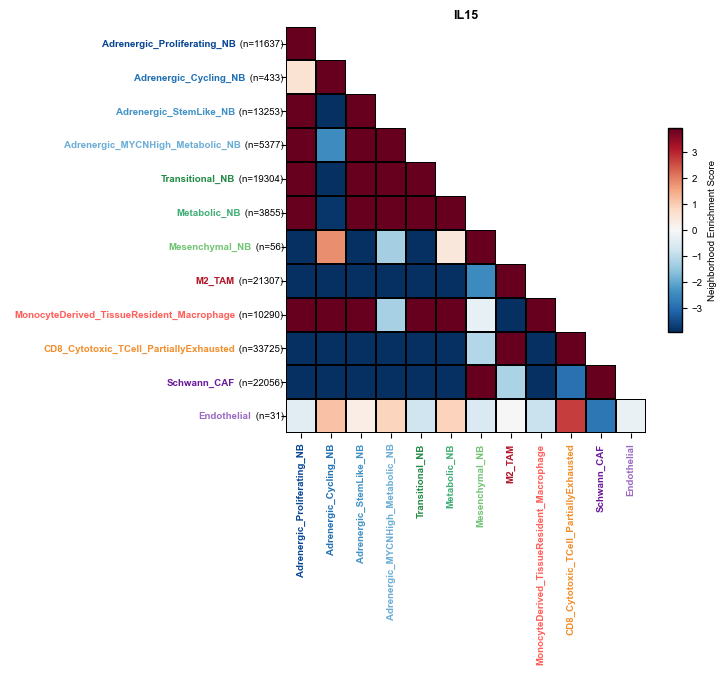

In [12]:
cond = 'IL15'
triangle = InteractionMatrixHeatmap(
    adata_clean[adata_clean.obs['Condition'] == cond],
    celltype_col="annotation_v1",
    colormap = annotation_colors,
    vmax_percentile=30,
    mask_diagonal=False,
    n_perms=1000,
    n_jobs=58,
)
triangle.compute()
triangle.cell_counts
triangle.plot(show_counts=True,title = cond)

  0%|          | 0/1000 [00:00<?, ?/s]

Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.


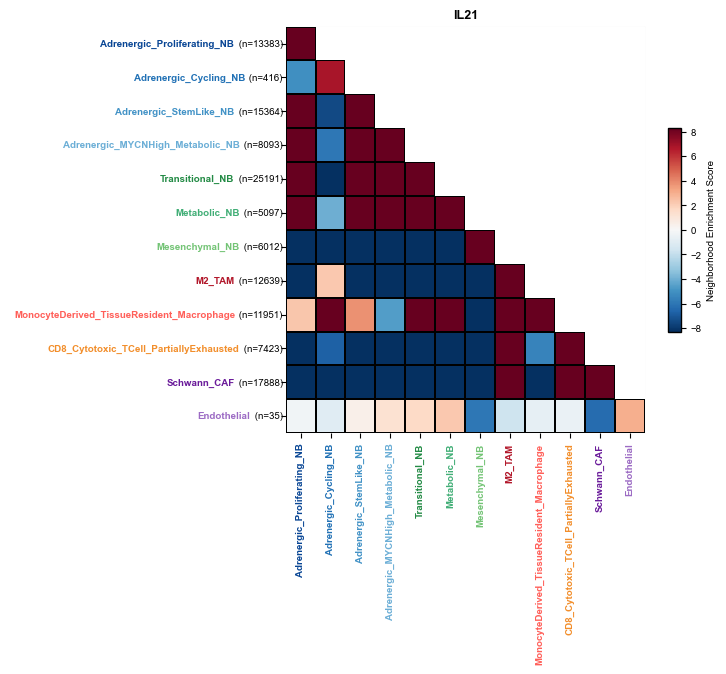

In [13]:
cond = 'IL21'
triangle = InteractionMatrixHeatmap(
    adata_clean[adata_clean.obs['Condition'] == cond],
    celltype_col="annotation_v1",
    colormap = annotation_colors,
    vmax_percentile=30,
    mask_diagonal=False,
    n_perms=1000,
    n_jobs=58,
)
triangle.compute()
triangle.cell_counts
triangle.plot(show_counts=True,title = cond)

  0%|          | 0/1000 [00:00<?, ?/s]

Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.


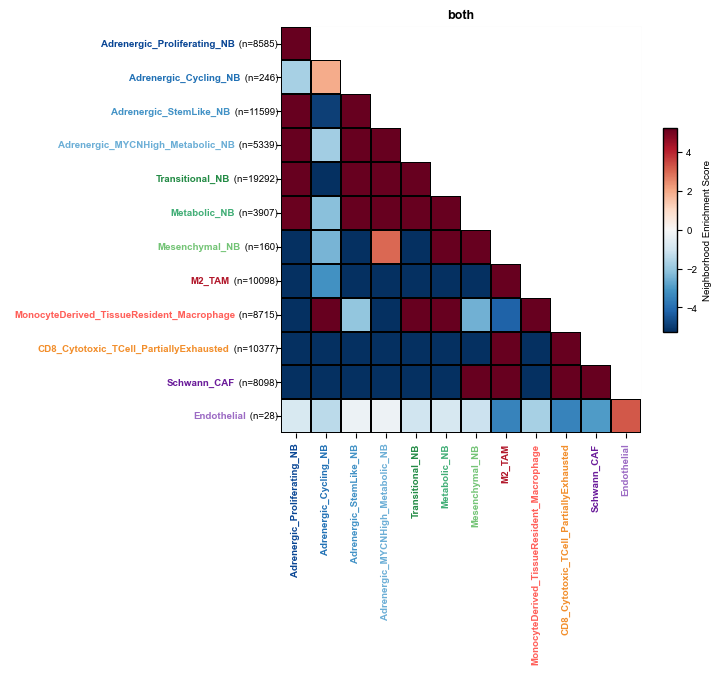

In [14]:
cond = 'both'
triangle = InteractionMatrixHeatmap(
    adata_clean[adata_clean.obs['Condition'] == cond],
    celltype_col="annotation_v1",
    colormap = annotation_colors,
    vmax_percentile=30,
    mask_diagonal=False,
    n_perms=1000,
    n_jobs=58,
)
triangle.compute()
triangle.cell_counts
triangle.plot(show_counts=True,title = cond)

  0%|          | 0/1000 [00:00<?, ?/s]

Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.


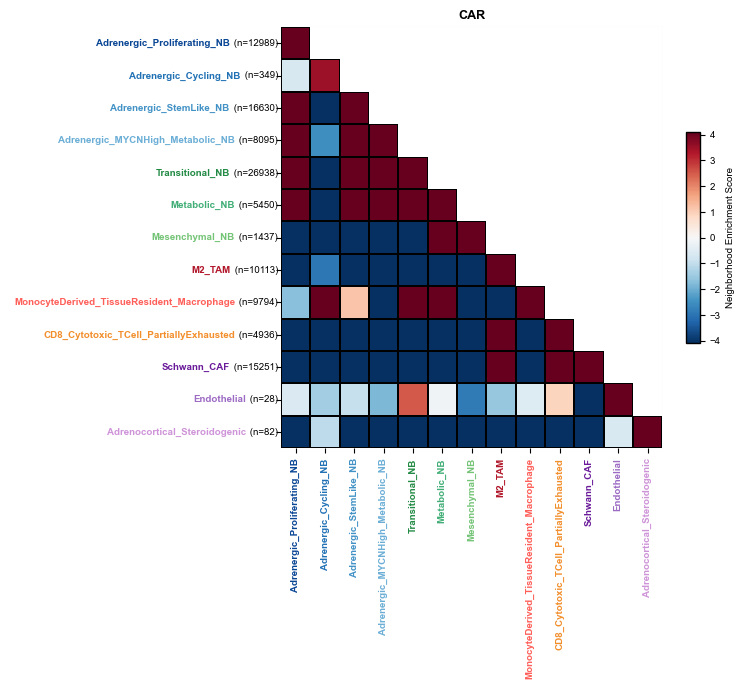

In [15]:
cond = 'CAR'
triangle = InteractionMatrixHeatmap(
    adata_clean[adata_clean.obs['Condition'] == cond],
    celltype_col="annotation_v1",
    colormap = annotation_colors,
    vmax_percentile=20,
    mask_diagonal=False,
    n_perms=1000,
    n_jobs=58,
)
triangle.compute()
triangle.cell_counts
triangle.plot(show_counts=True,title = cond)

  0%|          | 0/1000 [00:00<?, ?/s]

Numba: Attempted to fork from a non-main thread, the TBB library may be in an invalid state in the child process.


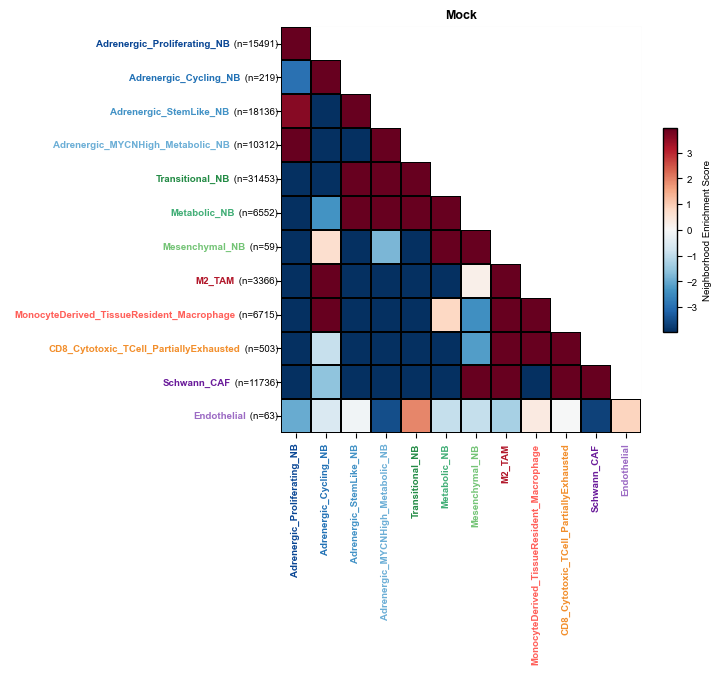

In [16]:
cond = 'Mock'
triangle = InteractionMatrixHeatmap(
    adata_clean[adata_clean.obs['Condition'] == cond],
    celltype_col="annotation_v1",
    colormap = annotation_colors,
    vmax_percentile=30,
    mask_diagonal=False,
    n_perms=1000,
    n_jobs=58,
)
triangle.compute()
triangle.cell_counts
triangle.plot(show_counts=True,title = cond)

In [17]:
color_map = {# Neuroblastoma — adrenergic states: blues
            "Adrenergic_Proliferating_NB": "#084594",
            "Adrenergic_Cycling_NB": "#2171B5",
            "Adrenergic_StemLike_NB": "#4292C6",
            "Adrenergic_MYCNHigh_Metabolic_NB": "#6BAED6",

            # Neuroblastoma — transitional / mesenchymal states: greens
            "Transitional_NB": "#238B45",
            "Metabolic_NB": "#41AE76",
            "Mesenchymal_NB": "#74C476",

            # Myeloid — reds
            "M2_TAM": "#B2182B",
            "MonocyteDerived_TissueResident_Macrophage": "#FF5F59",

            # Lymphoid — orange
            "CD8_Cytotoxic_TCell_PartiallyExhausted": "#F28E2B",

            # Stromal / adrenal — purples
            "Schwann_CAF": "#6A1B9A",
            "Endothelial": "#9C6BC4",
            "Adrenocortical_Steroidogenic": "#CE93D8",}

nb_color = {"Adrenergic_Proliferating_NB": "#084594",
            "Adrenergic_Cycling_NB": "#2171B5",
            "Adrenergic_StemLike_NB": "#4292C6",
            "Adrenergic_MYCNHigh_Metabolic_NB": "#6BAED6",

            # Neuroblastoma — transitional / mesenchymal states: greens
            "Transitional_NB": "#238B45",
            "Metabolic_NB": "#41AE76",
            "Mesenchymal_NB": "#74C476",}
target_color = {"M2_TAM": "#B2182B",
            "MonocyteDerived_TissueResident_Macrophage": "#FF5F59", 
            "CD8_Cytotoxic_TCell_PartiallyExhausted": "#F28E2B",}

In [18]:
pathad = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
adata_clean.write_h5ad(os.path.join(pathad, "adata_nb_processed_v2.h5ad"))

In [18]:
ad = adata_clean.copy()

In [35]:
from helper.cooccurrence_compute import compute_celltype_cooccurrence, plot_all_conditions_cooccurrence
from helper.triangle_heatmap import PUB_RC

In [20]:
ad = ad[~ad.obs['Condition'].isin(['Mock'])]

In [43]:
COOC_INTERVAL = np.arange(0, 100, 12)
MIN_CELLS = 15
label_col = 'annotation_v1'
CONDITION_ORDER = ['CAR', 'IL15', 'both', 'IL21']

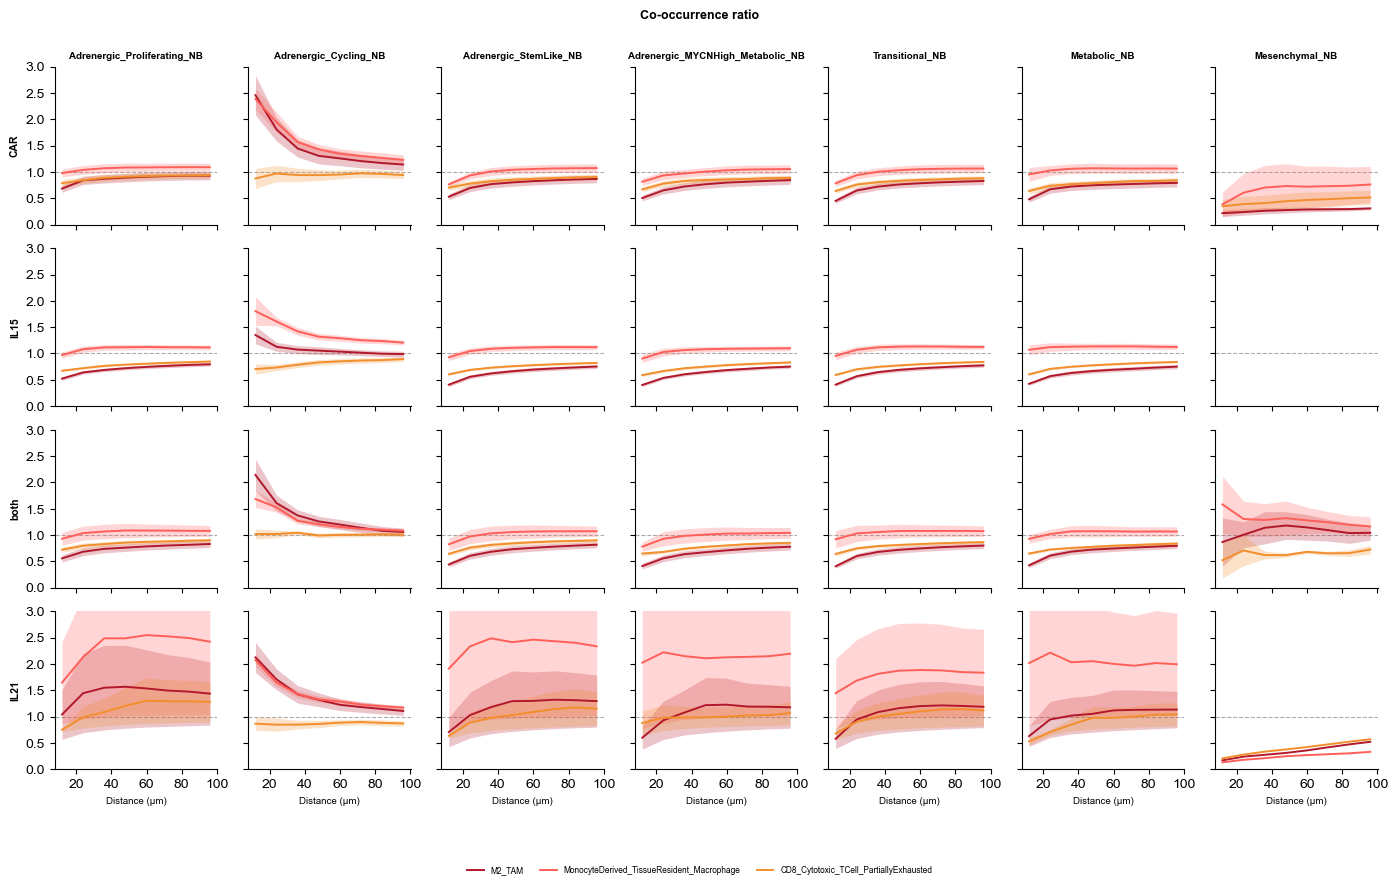

In [44]:
transf_cell_types = list(nb_color.keys())
target_cell_types = list(target_color.keys())

near_nb_cooc = compute_celltype_cooccurrence(
    ad, target_cell_types, transf_cell_types,
    interval=COOC_INTERVAL, sample_col='punch_id', condition_col='Condition',
    label_col=label_col, min_cells=MIN_CELLS,
)
if near_nb_cooc.empty:
    near_nb_summary = pd.DataFrame(columns=["cell_type", "anchor", "condition", "distance", "mean", "sem", "n"])
else:
    g = near_nb_cooc.groupby(["cell_type", "anchor", "condition", "distance"])["ratio"]
    near_nb_summary = g.agg(
        mean="mean", sem=lambda x: x.std(ddof=1) / np.sqrt(len(x)) if len(x) > 1 else 0.0, n="count",
    ).reset_index()

plot_all_conditions_cooccurrence(near_nb_summary, CONDITION_ORDER, transf_cell_types, target_color, PUB_RC)

In [1]:
# mamba activate squidpy-voyagerpy_v1 
import scanpy as sc
import numpy as np
import os
import matplotlib.pyplot as plt

import pandas as pd

import alphashape as alphashape

In [4]:
import h5py
pathad = '/data/HiTIF/data/spatialomics/neuroblastoma/data/andata_orig'
fn = os.path.join(pathad, "adata_nb_processed_v2.h5ad")

with h5py.File(fn, "a") as f:
    for key in [
        "uns/log1p/base",
        "uns/pca/params/mask_var",
        "uns/spatial_neighbors/params/transform",
    ]:
        if key in f:
            del f[key]

andata = sc.read_h5ad(fn)

In [5]:
andata.obs['Condition'].unique()

['IL15', 'IL21', 'both', 'CAR', 'Mock']
Categories (5, object): ['Mock' < 'CAR' < 'IL15' < 'IL21' < 'both']

In [ ]:
adata_concat_rest = adata_concat[adata_concat.obs['Condition'].isin(['Pmel1','Pmel1.Il21', 'Pmel1.Il15', 'Pmel1.Il21.Il15', 'Mock'])].copy() 

In [6]:
andata.obs.columns

Index(['cell_id', 'transcript_counts', 'control_probe_counts',
       'genomic_control_counts', 'control_codeword_counts',
       'unassigned_codeword_counts', 'deprecated_codeword_counts',
       'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count',
       'segmentation_method', 'region', 'z_level', 'cell_labels', 'sample_lab',
       'mouse_id', 'Condition', 'Type', 'punch_id', 'n_genes_by_counts',
       'cluster_30neig_r07', 'stlieden_ratio1p5_r13', 'annotation_v1',
       '0_subclusters_res_0p5'],
      dtype='object')

In [ ]:
def ct_table(adata_concat, ct_key='cell_type'):
    '''
    Generates a dataframe for cell type abundance analysis across conditions and batches.

    This function filters the input AnnData object for specific batches and conditions,
    then calculates the abundance of a specified cell type relative to the total number
    of cells per treatment-batch group. Pseudo-counts are added to avoid zero values.

    Parameters
    ----------
    adata_concat : AnnData
        The input AnnData object containing single-cell data.
    ct_key : str, default 'cell_type'
        The specific cell type name (found in adata.obs['cell_type']) to analyze.
        
    Returns
    -------
    pd.DataFrame
        A DataFrame with columns:
        - 'treatment_batch': Combined condition, day, and batch.
        - 'n_cells': Total cells in the group.
        - 'treatment': Combined condition and day.
        - 'n_cells_ct': Count of the specific cell type (with pseudo-count +1).
        - 'batch': Batch identifier.
        - 'celltype': The name of the cell type analyzed.
    '''
    adata_concat.obs['Condition'] = adata_concat.obs['Condition'].astype(str)
    batch_l = ['58','33','32','9']
    adata_concat = adata_concat[~adata_concat.obs['batch'].isin(batch_l)]
    adata_concat_rest = adata_concat[adata_concat.obs['Condition'].isin(['Pmel1','Pmel1.Il21', 'Pmel1.Il15', 'Pmel1.Il21.Il15', 'Mock'])].copy() 
    df = adata_concat_rest.obs.copy()
    def catTostring(colList):
        for col in colList:
            df[col] = df[col].astype(str)
    colList = ['cell_type','batch','Harvest_Day', 'Condition']
    catTostring(colList)
    df['treatment'] = df['Condition'] + '_' + df['Harvest_Day']
    df.loc[df['cell_type']==ct_key].groupby('treatment').size()
    df['treatment_batch'] = df['Condition'] + '_' + df['Harvest_Day'] + '_' + df['batch']
    df_plt = pd.DataFrame({'treatment_batch':df.groupby('treatment_batch').size().index.values, 'n_cells':df.groupby('treatment_batch').size(),"treatment":df.groupby(['treatment_batch','treatment'], as_index=False)['treatment'].size()['treatment'].values}).reset_index(drop=True)
    df_plt['n_cells_ct'] = df.loc[df['cell_type']==ct_key].groupby('treatment_batch').size().reset_index(drop=True)
    cond_order = ['Mock','Pmel1', 'Pmel1.Il21', 'Pmel1.Il15', 'Pmel1.Il21.Il15']
    day_order =['4','8']
    treatment_order = [f"{c}_{d}" for c in cond_order for d in day_order]
    df_plt["treatment"] = pd.Categorical(
        df_plt["treatment"],
        categories=treatment_order,
        ordered=True,
    )
    df_plt['batch'] = [re.sub(r'.*_', '', b) for b in df_plt['treatment_batch']]
    # add psudo counts to avoid zero counts
    df_plt['n_cells_ct'] = df_plt['n_cells_ct'] + 1
    df_plt['celltype'] = ct_key
    return df_plt

In [ ]:
def plot_celltype_stacked_100(
    adata,
    legend_order,
    ct_key="annotation_v1",
    condition_key="Condition",
    #day_key_candidates=("harvest_day", "Harvest_Day"),
    batch_key_candidates=("punch_id", "mouse_id"),
    colors_uns_key="cell_type_colors",
    conditions_keep=("Pmel1", "Pmel1.Il21", "Pmel1.Il15", "Pmel1.Il21.Il15", "Mock"),
    exclude_batches=("58","33","32","9"),
    make_separate_figs=True,
):
    """
    Stacked bars normalized to 100% per Condition, split by day (two panels: day 4 and day 8).
    Uses colors from adata.uns[colors_uns_key] (Scanpy convention).
    """
    # day_key = _pick_col(adata, list(day_key_candidates))
    # batch key is optional; only used for excluding batches if present
    batch_key = None
    for c in batch_key_candidates:
        if c in adata.obs.columns:
            batch_key = c
            break

    # copy obs only
    df = adata.obs[[ct_key, condition_key, day_key] + ([batch_key] if batch_key else [])].copy()
    df[condition_key] = df[condition_key].astype(str)
    df[day_key] = df[day_key].astype(str)
    df[ct_key] = df[ct_key].astype(str)

    # filter conditions
    if conditions_keep is not None:
        df = df[df[condition_key].isin(list(conditions_keep))].copy()

    # exclude specific batches if possible
    if batch_key is not None and exclude_batches:
        df = df[~df[batch_key].astype(str).isin(list(exclude_batches))].copy()

    # enforce x-order (Condition)
    cond_order = list(conditions_keep) if conditions_keep is not None else sorted(df[condition_key].unique())
    df[condition_key] = pd.Categorical(df[condition_key], categories=cond_order, ordered=True)

    # color map from uns
    ct_color_map = _get_ct_color_map(adata, ct_key=ct_key, colors_uns_key=colors_uns_key)

    # final legend order (only keep those that exist)
    present_cts = set(df[ct_key].unique())
    legend_order_present = [ct for ct in legend_order if ct in present_cts]

    # days to plot (prefer 4 then 8 if present)
    day_vals = list(pd.unique(df[day_key]))
    preferred_days = [d for d in ["4", "8"] if d in day_vals]
    other_days = [d for d in day_vals if d not in preferred_days]
    days_to_plot = preferred_days + sorted(other_days)

    # publication-ish styling
    plt.rcParams.update({
        "font.size": 7,
        "axes.titlesize": 8,
        "axes.labelsize": 7,
        "xtick.labelsize": 7,
        "ytick.labelsize": 7,
        "legend.fontsize": 7,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
    })

    def _make_panel(ax, d):
        ddf = df[df[day_key] == d].copy()

        # counts per (Condition, cell_type)
        tab = pd.crosstab(ddf[condition_key], ddf[ct_key])  # rows=Condition, cols=cell_type
        tab = tab.reindex(cond_order)  # enforce x order

        # keep only legend-ordered columns (and only those present)
        tab = tab.reindex(columns=legend_order_present, fill_value=0)

        # normalize to 100%
        denom = tab.sum(axis=1).replace(0, np.nan)
        frac = (tab.div(denom, axis=0) * 100).fillna(0)

        x = np.arange(frac.shape[0])
        bottom = np.zeros(frac.shape[0], dtype=float)

        for ct in frac.columns:
            ax.bar(
                x,
                frac[ct].values,
                bottom=bottom,
                width=0.85,
                color=ct_color_map.get(ct, "#999999"),
                edgecolor="white",
                linewidth=0.3,
                label=ct,
            )
            bottom += frac[ct].values

        ax.set_ylim(0, 100)
        ax.set_ylabel("Cell type (%)")
        ax.set_title(f"Day {d}")
        ax.set_xticks(x)
        ax.set_xticklabels([str(c) for c in frac.index], rotation=35, ha="right")
        ax.grid(axis="y", linewidth=0.3, alpha=0.3)
        ax.set_axisbelow(True)
        return ax

    if make_separate_figs:
        figs = []
        for d in days_to_plot[:2]:  # requested day 4 and day 8; will plot up to first two days found
            fig, ax = plt.subplots(figsize=(3.35, 2.6))  # single-column friendly
            _make_panel(ax, d)

            # legend outside
            handles, labels = ax.get_legend_handles_labels()
            ax.legend(
                handles, labels,
                title=None,
                loc="center left",
                bbox_to_anchor=(1.02, 0.5),
                frameon=False,
            )

            fig.tight_layout()
            figs.append(fig)
        return figs

    else:
        # two panels in one figure (day 4 + day 8)
        n = min(2, len(days_to_plot))
        fig, axes = plt.subplots(1, n, figsize=(6.8, 2.6), sharey=True)  # double-column width-ish
        if n == 1:
            axes = [axes]
        for ax, d in zip(axes, days_to_plot[:n]):
            _make_panel(ax, d)

        handles, labels = axes[-1].get_legend_handles_labels()
        fig.legend(
            handles, labels,
            loc="center left",
            bbox_to_anchor=(1.01, 0.5),
            frameon=False,
        )
        fig.tight_layout()
        return fig